<img src="images/highway2.jpg" width="90%">

# Predictive Analytics & Forecasting
> Executive Master in Business Analytics and AI
> - Project 2026
> - Rita P. Ribeiro - University of Porto | INESC TEC
> - October 2026


## Description
You are part of an analytics team supporting a national road-safety authority. The organization wants to understand how historical highway-accident data can be used to support better road-safety decisions.

# Task 1 - Problem Definition

### Highway Accidents Dataset
* The dataset contains historical records of highway accidents in Brazil between 2007 and 2025.
* Each observation corresponds to an individual accident described by 23 variables covering the date and location of the accident, road characteristics and infrastructure, and accident severity.
* For this project, you are provided with a sample of 150,000 accident records, preserving the temporal structure and main characteristics of the original dataset. 
    * Table 1 presents the data dictionary, with a description of each variable.

-------

# Task 2 - Data Understanding and Data Preparation

**Quarterly emergency-resource planning for weekends and holidays**

> Each quater, we forecast how many accidents with injuries or fatalities each of Brazil's 5 macro-regions will have on every weekend day and holiday of the next quarter. Regional emergency planner will use the forcast to decide how many ambulances, rescue team and patrols to have ready. **The model** count total accidents with injuries and fatality per region per day. The forecast is made **1 motnth before the quarter starts**.


**Contents**
1. Set up and decisions carried over from Task 1
2. Data structure and quality
3. Monthly trend
4. Region
5. Target table
6. Feature engineering
   - 6.1 Holiday and weekend calendar
   - 6.2 Weather and climate per region
   - 6.3 History features
   - 6.4 Final modelling table
7. How the modelling table is used

Modelling (models, training, evaluation, ensemble) is in `03_Modelling.ipynb`.

-------
## 1. Set up and decisions carried over from Task 1

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.easter import easter
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
import requests_cache


ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/raw/highway_accidents.csv"
OUT = ROOT / "data/processed"
OUT.mkdir(parents=True, exist_ok=True)

# Shared calendar and region functions live in src/features.py (also imported by 03_Modelling.ipynb)
sys.path.append(str(ROOT / "src"))

# ---- decisions agreed in Task 1 ----
LEAD_MONTHS = 1         # data cutoff (ref_date) = 1 month before the quarter starts
WINDOW_DAYS = 3         # holiday window = holiday date +/- 3 days
QUARTER_DAYS = 91       # "last quarter" = the 91 days up to the cutoff
ERA_START = pd.Timestamp("2018-04-01")   # start of the modelling period
# Target = accidents with victims = injury (1) or fatal (2) per region per day. Class 0 is excluded. 

REGIONS = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

# plotting: restrained palette, light grid, no top/right spines
BLUE, ORANGE, GREY, DARK = "#2F6DB5", "#D9622B", "#8A8F98", "#222222"
REGION_COLORS = dict(zip(REGIONS, [BLUE, ORANGE, "#1B998B", "#7A5FB5", "#C79A1E"]))
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E3E5E8", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": DARK, "text.color": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "legend.frameon": False, "figure.figsize": (8, 3.6),
})
pd.set_option("display.max_columns", 50, "display.width", 140, "display.float_format", "{:,.3f}".format)

--------
## 2. Data structure and Data Quality

Added a unique accident ID
* Every row gets a unique accident_id, added before any filtering, so rows can be traced through cleaning and joins and checked for duplicates. 
* It is a row key only and is excluded from model features.

* when building the model, drop it with the other non-features

> X = model_df.drop(columns=["accident_id", "target"])  # plus anything else that isn't a feature 

In [2]:
raw = pd.read_csv(DATA, parse_dates=["date"])
raw.insert(0, "accident_id", range(1, len(raw) + 1))   # row key, added before any filtering or sorting
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns | {raw.date.min().date()} to {raw.date.max().date()} | sorted by date: {raw.date.is_monotonic_increasing}")
raw.head()

150,000 rows x 24 columns | 2007-01-01 to 2025-12-31 | sorted by date: True


,accident_id,date,km,road_direction,roadway_type,area_type,latitude,longitude,time_of_day,highway_type,Uphill,Crossing,Curve,Downhill,Temporary_Detour,Roadworks,Road_Intersection,Bridge,Straight,Regulated_Uturn,Roundabout,Tunnel,Overpass,accident_classification
0,1,2007-01-01,45.500,1.000,0.000,0.000,NaN,NaN,0,3.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0
1,2,2007-01-01,83.900,1.000,0.000,1.000,NaN,NaN,1,3.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1
2,3,2007-01-01,11.000,0.000,0.000,0.000,NaN,NaN,3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0
3,4,2007-01-01,180.000,1.000,2.000,1.000,NaN,NaN,0,4.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1
4,5,2007-01-01,230.600,0.000,2.000,0.000,NaN,NaN,0,3.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0


In [3]:
# make a copy of the raw data
raw_copy = raw.copy()

In [4]:
raw.dtypes

accident_id                         int64
date                       datetime64[us]
km                                float64
road_direction                    float64
roadway_type                      float64
area_type                         float64
latitude                          float64
longitude                         float64
time_of_day                         int64
highway_type                      float64
Uphill                            float64
Crossing                          float64
Curve                             float64
Downhill                          float64
Temporary_Detour                  float64
Roadworks                         float64
Road_Intersection                 float64
Bridge                            float64
Straight                          float64
Regulated_Uturn                   float64
Roundabout                        float64
Tunnel                            float64
Overpass                          float64
accident_classification           

### 2.1 Missing Values Checks

In [5]:
roles = {
    "date": "calendar key (known in advance)",
    "km": "quality checks only (no use as input: unreliable, accident-level)",
    "road_direction": "not used",
    "roadway_type": "severity context, kept in accidents.csv",
    "area_type": "severity context, kept in accidents.csv",
    "latitude": "mapping to macro-region only",
    "longitude": "mapping to macro-region only",
    "time_of_day": "severity context, kept in accidents.csv",
    "highway_type": "not used for now",
    "accident_classification": "TARGET: class 1 or 2 counts as an accident with victims; class 0 (no injury) is excluded",
}
ROAD_FEATURES = ["Uphill", "Crossing", "Curve", "Downhill", "Temporary_Detour", "Roadworks",
                 "Road_Intersection", "Bridge", "Straight", "Regulated_Uturn", "Roundabout",
                 "Tunnel", "Overpass"] # Ivana: added this here for the new id
for c in ROAD_FEATURES:
    roles[c] = "severity context, kept in accidents.csv" # if c in ["Curve", "Roadworks"] else "accident-level road feature: aggregate or drop"

dictionary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean() * 100,
    "unique": raw.nunique(),
    "role": pd.Series(roles),
})
dictionary

,dtype,missing,missing_%,unique,role
Bridge,float64,1,0.001,2,"severity context, kept in accidents.csv"
Crossing,float64,1,0.001,2,"severity context, kept in accidents.csv"
Curve,float64,1,0.001,2,"severity context, kept in accidents.csv"
Downhill,float64,1,0.001,2,"severity context, kept in accidents.csv"
Overpass,float64,1,0.001,2,"severity context, kept in accidents.csv"
Regulated_Uturn,float64,1,0.001,2,"severity context, kept in accidents.csv"
Road_Intersection,float64,1,0.001,2,"severity context, kept in accidents.csv"
Roadworks,float64,1,0.001,2,"severity context, kept in accidents.csv"
Roundabout,float64,1,0.001,2,"severity context, kept in accidents.csv"
Straight,float64,1,0.001,2,"severity context, kept in accidents.csv"


In [6]:
# Visualize the feature of the roads and the % of accidents, also the % of fatalities
# from april 2018
recent = raw[raw["date"] >= "2018-04-01"]
is_fatal = recent["accident_classification"] == 2
print(f"All accidents {is_fatal.mean() * 100:.1f}% fatal")

severity = pd.DataFrame({
    "accidents" : recent[ROAD_FEATURES].sum().astype(int),
    "% of accidents" : recent[ROAD_FEATURES].mean() * 100,
    "fatal %" : recent[ROAD_FEATURES].apply(lambda col: is_fatal[col == 1].mean() * 100),
}).rename_axis("feature").sort_values("fatal %", ascending=False)

severity.round(1)

All accidents 7.1% fatal


,accidents,% of accidents,fatal %
feature,,,
Bridge,309,0.900,10.000
Downhill,3033,8.400,9.400
Uphill,2318,6.400,8.100
Curve,6744,18.700,7.700
Straight,24831,68.800,7.300
Roadworks,620,1.700,6.500
Overpass,474,1.300,4.200
Temporary_Detour,134,0.400,3.700
Road_Intersection,2271,6.300,3.500


- Curve is close to average, and Roadworks is slightly below it.
- The features that actually differ are Downhill and Bridge (more deadly), and Intersection and Roundabout (less deadly, since traffic there is slower).
- So the choice looks like road-safety intuition (curves and roadworks are classic risk factors), not something the data shows.
- The share of accidents with any injury barely changes between features (81–86%). These columns mostly affect whether someone dies, not whether someone is hurt.

Ivana - Suggestion:
Keep all the features, they cost almost nothing in memory.
And whoever analyses severity later can decide which to use. I changed the loop in the 2.1 cell so every feature gets the same role:


> for c in ROAD_FEATURES:
    roles[c] = "severity context, kept in accidents.csv"

In [7]:
missing = raw[raw.latitude.isna() | raw.longitude.isna()]
present = raw[raw.latitude.notna() & raw.longitude.notna()]

print(f"Missing coordinates: {len(missing):,} rows | {missing.date.min().date()} to {missing.date.max().date()}")
print(f"Present coordinates: {len(present):,} rows | {present.date.min().date()} to {present.date.max().date()}")
print("rows with a missing road_direction missing:", raw.road_direction.isna().sum())

Missing coordinates: 106,237 rows | 2007-01-01 to 2016-12-31
Present coordinates: 43,763 rows | 2017-01-01 to 2025-12-31
rows with a missing road_direction missing: 90


**Decision** Use Data from 2017 to 2025 for regional prediction

### 2.2 Coordinates, Km, Duplicates

coordinates outside the Brazil bounding box: 3


,date,latitude,longitude,km
106275,2017-01-02,0.000,0.000,418.000
106352,2017-01-07,13.000,40.000,658.000
106364,2017-01-07,-85.049,-40.000,827.000


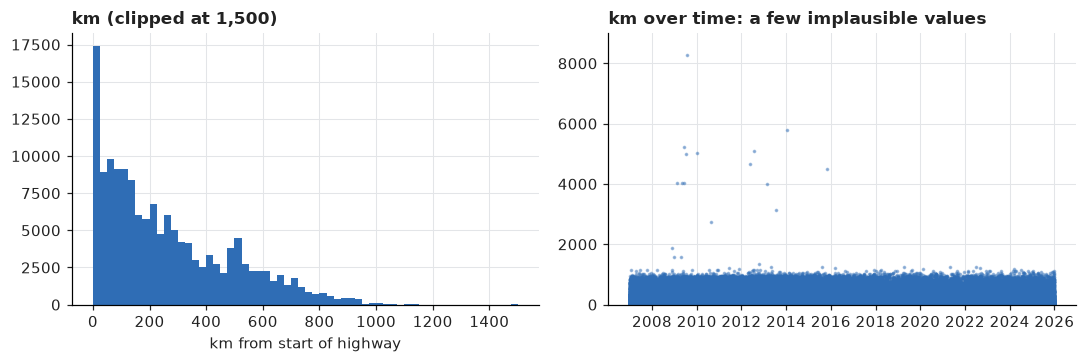

km quantiles: {0.5: 202.0, 0.9: 603.0, 0.99: 886.0, 0.999: 1033.0} max: 8280.0
km > 1,100 (above the 99.9th percentile): 71 rows; the longest federal highways are about 4,500 km, so values above that are errors
exact duplicate rows: 49 (the source has no accident ID, so two real accidents at the same km on the same day look identical)


In [8]:
c = raw.dropna(subset=["latitude"])
inside = c.latitude.between(-34, 6) & c.longitude.between(-74, -32)
print(f"coordinates outside the Brazil bounding box: {(~inside).sum()}")
display(c.loc[~inside, ["date", "latitude", "longitude", "km"]])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(raw.km.clip(upper=1500), bins=60, color=BLUE)
axes[0].set(title="km (clipped at 1,500)", xlabel="km from start of highway")
axes[1].scatter(raw.date, raw.km, s=2, color=BLUE, alpha=0.4)
axes[1].set(title="km over time: a few implausible values", ylim=(0, 9000))
plt.tight_layout(); plt.show()

print("km quantiles:", raw.km.quantile([.5, .9, .99, .999]).round(0).to_dict(), "max:", raw.km.max())
print(f"km > 1,100 (above the 99.9th percentile): {(raw.km > 1100).sum()} rows; the longest federal highways are about 4,500 km, so values above that are errors")
# print(f"exact duplicate rows: {raw.duplicated().sum()} (no accident ID, so two real accidents at the same km on the same day look identical)")
dups = raw.drop(columns="accident_id").duplicated().sum()   # ignore our own row key, it makes every row unique
print(f"exact duplicate rows: {dups} (the source has no accident ID, so two real accidents at the same km on the same day look identical)")

- **Invalid coordinates:** 3 rows (e.g. latitude −85, longitude 40, or 0/0). They are excluded from the regional data.
- **`km`** has values up to 8,280 and a handful above any real highway length. We never use `km` as an input; outliers are only flagged.
- **Duplicates:** 49 exact duplicates. Without an accident ID we cannot tell a double entry from two accidents at the same spot, and 49 of 150,000 is negligible, so they are **kept**.

###  2.2.1. Data quality decisions

### Invalid coordinates

Three accidents have a location that cannot be in Brazil:

| Date       | Latitude | Longitude | Where that is                                      |
|------------|---------:|----------:|----------------------------------------------------|
| 2017-01-02 |        0 |         0 | Atlantic Ocean off Africa (a typical "empty" default value) |
| 2017-01-07 |       13 |        40 | Ethiopia                                           |
| 2017-01-07 |      −85 |       −40 | Antarctica                                         |

**Decision:** these 3 accidents are excluded from the regional data. Their region is found from the coordinates (nearest reference city), and a point outside Brazil would be assigned to a region at random. Only 1 of the 3 had victims, so the effect on the daily counts is negligible.

### Implausible `km` values

`km` is the position of the accident along the highway. Half of the values are below 202 km and 99.9% are below about 1,033 km, but 7 rows are above 4,500 km (up to 8,280 km). That is longer than any Brazilian federal highway, so these are typing errors.

**Decision:** the rows are kept and the values are left as they are. `km` is not a model input, and the region comes from the coordinates, not from `km`. A wrong `km` does not mean the accident did not happen, so the row still counts correctly. Removing these rows would lose real accidents for no benefit.

### Duplicate rows

There are 49 pairs of rows that are identical in every column (the `accident_id` we added is ignored for this check). All of them are from 2007–2014, none of them have coordinates, and 41 of the 49 are class 0 (no injuries).

**Decision:** the duplicates are kept. The source has no accident ID, so we cannot tell a double entry from two real accidents on the same stretch of road on the same day. None of the duplicates enter the model data (April 2018 onward, with coordinates), so removing them would not change any result.

## 3. Exploratory Data Analytis (EDA)

### 3.1. Monthly trend

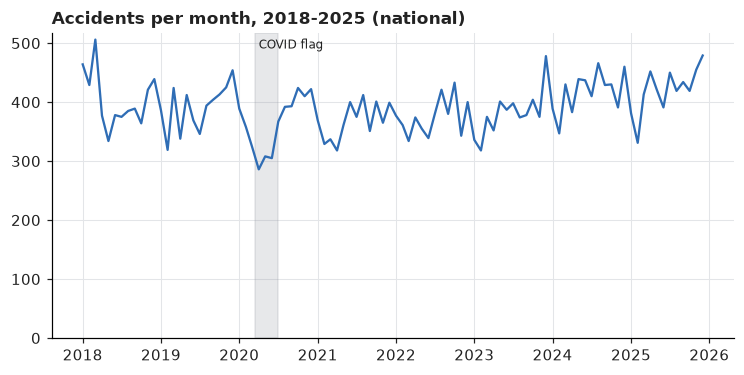

date,2019-10-01,2019-11-01,2019-12-01,2020-01-01,2020-02-01,2020-03-01,2020-04-01,2020-05-01,2020-06-01,2020-07-01,2020-08-01,2020-09-01,2020-10-01,2020-11-01,2020-12-01,2021-01-01,2021-02-01,2021-03-01
accidents,413,425,454,389,358,324,286,308,305,367,392,393,424,410,422,369,329,337


In [9]:
monthly = raw[raw.date >= "2018-01-01"].groupby(raw.date.dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly, color=BLUE)
ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-30"), color=GREY, alpha=0.2)
ax.text(pd.Timestamp("2020-04-01"), monthly.max() * 0.97, "COVID flag", fontsize=8)
ax.set(title="Accidents per month, 2018-2025 (national)", ylim=(0, None))
plt.show()
monthly["2019-10":"2021-03"].to_frame("accidents").T

During Covide time, the volume was around 15-20% lower in March, April, May and June 2020 compare with 2019

### 3.2. Daily trend including those without victims

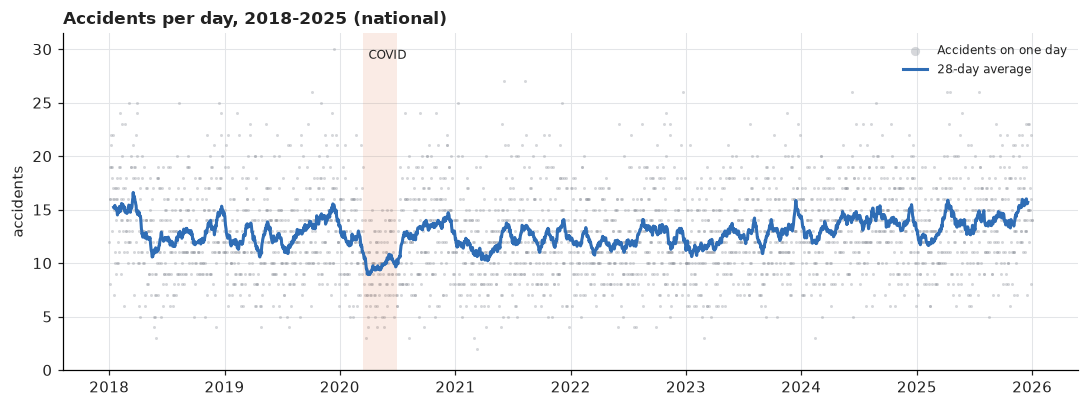

,avg accidents per day
2019-10,13.300
2019-11,14.200
2019-12,14.600
2020-01,12.500
2020-02,12.300
2020-03,10.500
2020-04,9.500
2020-05,9.900
2020-06,10.200
2020-07,11.800


In [10]:
# Daily counts are very noisy (2 to 30 accidents a day), so each day is a faint dot
# and the trend is a 28-day average on top
daily = raw[(raw.date >= "2018-01-01")].groupby("date").size()
daily = daily.reindex(pd.date_range(daily.index.min(), "2025-12-31"), fill_value=0)   # days with no accident = 0
trend = daily.rolling(28, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(daily.index, daily, s=4, color=GREY, alpha=0.35, linewidths=0, label="Accidents on one day")
ax.plot(trend.index, trend, color=BLUE, linewidth=2, label="28-day average")
ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-30"), color=ORANGE, alpha=0.12, linewidth=0)
ax.text(pd.Timestamp("2020-04-01"), daily.max() * 0.97, "COVID", fontsize=8)
ax.set(title="Accidents per day, 2018-2025 (national)", ylabel="accidents", ylim=(0, daily.max() * 1.05))
ax.legend(loc="upper right", fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()


# Average accidents per day for each month around COVID
covid = daily["2019-10":"2021-03"].resample("MS").mean().round(1)
covid.index = covid.index.strftime("%Y-%m")
covid.to_frame("avg accidents per day")

* The chart shows a clear seasonal pattern, with peaks around December–January and around Easter, a dip in mid-year, the COVID drop in 2020, and a slow rise from 2023 on. 
* That supports adding the climate and month features in section 6.
* This chart counts all accidents, including those without victims. If you want it to match your target, change the first line to raw[(raw.date >= "2018-01-01") & (raw.accident_classification >= 1)].

### 3.3. Daily trend excluding those without victims

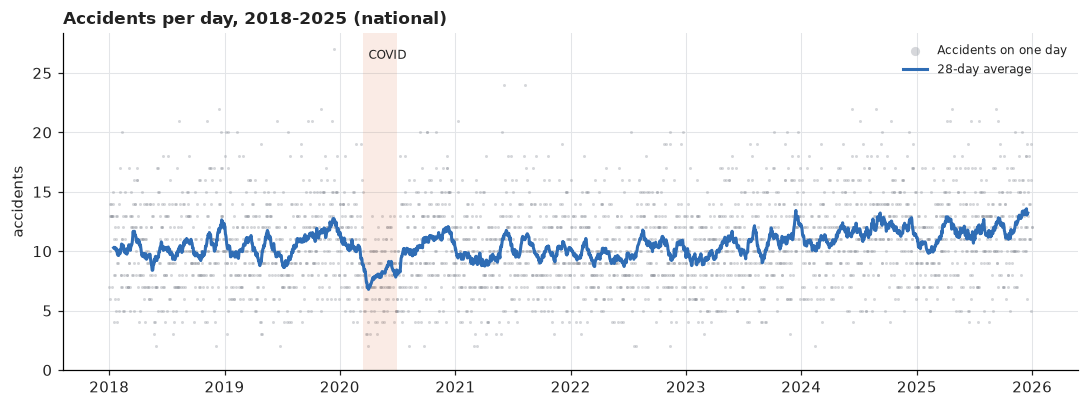

,avg accidents per day
2019-10,11.000
2019-11,11.700
2019-12,12.200
2020-01,10.800
2020-02,10.300
2020-03,8.500
2020-04,7.700
2020-05,8.400
2020-06,8.400
2020-07,9.600


In [11]:
# Daily counts are very noisy (2 to 30 accidents a day), so each day is a faint dot
# and the trend is a 28-day average on top
daily1 = raw[(raw.date >= "2018-01-01") & (raw.accident_classification >= 1)].groupby("date").size()
daily1 = daily1.reindex(pd.date_range(daily1.index.min(), "2025-12-31"), fill_value=0)   # days with no accident = 0
trend = daily1.rolling(28, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(daily1.index, daily1, s=4, color=GREY, alpha=0.35, linewidths=0, label="Accidents on one day")
ax.plot(trend.index, trend, color=BLUE, linewidth=2, label="28-day average")
ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-30"), color=ORANGE, alpha=0.12, linewidth=0)
ax.text(pd.Timestamp("2020-04-01"), daily1.max() * 0.97, "COVID", fontsize=8)
ax.set(title="Accidents per day, 2018-2025 (national)", ylabel="accidents", ylim=(0, daily1.max() * 1.05))
ax.legend(loc="upper right", fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()


# Average accidents per day for each month around COVID
covid = daily1["2019-10":"2021-03"].resample("MS").mean().round(1)
covid.index = covid.index.strftime("%Y-%m")
covid.to_frame("avg accidents per day")

In [12]:
# what is the average for all the period october 2019 to March 2021 of covid of accidents with victims (injury or fatal) per day?
avg_accidents_per_day = daily1["2019-10":"2021-03"].mean().round(1)
avg_accidents_per_day

np.float64(10.1)

In [13]:
avg_accidents_per_day_without_victims = daily["2019-10":"2021-03"].mean().round(1)
avg_accidents_per_day_without_victims

np.float64(12.2)

During Covid time the avg accidents with victims per day dropped to 7.7 in April 2020, from 8.5 in March 2020, and then gradually increased to 8.4 in June 2020. The average for the entire period from October 2019 to March 2021 was 10.1 accidents per day. But the average for the same period in the dataframe without victims is 12.2. 

### 3.4. Outliers

In [14]:
# Check for outliers in the number of accidents per day with victims (injury or fatal) during the covid period (october 2019 to March 2021)
covid_period = daily1["2019-10":"2021-03"]
# Calculate the z-scores for the number of accidents per day
z_scores = (covid_period - covid_period.mean()) / covid_period.std()
# Identify the outliers (z-score > 3 or < -3)
outliers = covid_period[(z_scores > 3) | (z_scores < -3)]
outliers


2019-11-02    22
2019-12-14    27
dtype: int64

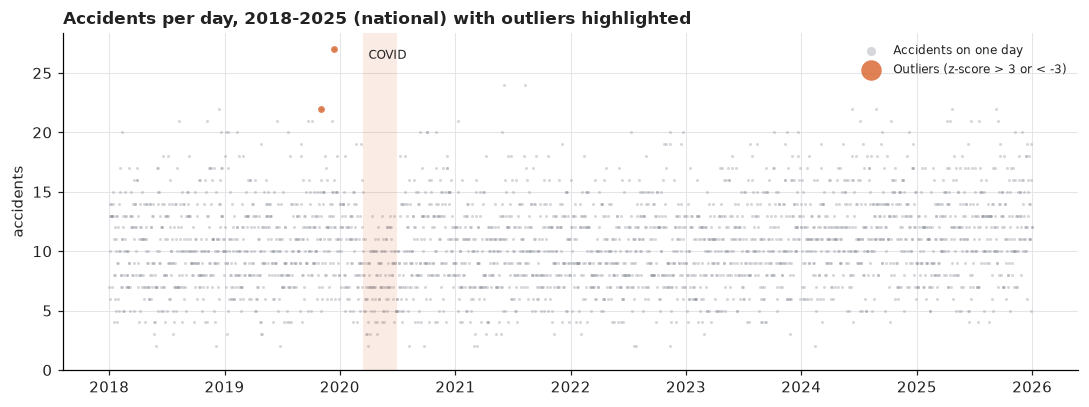

In [15]:
# visualize the outliers
plt.figure(figsize=(10, 3.8))
plt.scatter(daily1.index, daily1, s=4, color=GREY, alpha=0.35, linewidths=0, label="Accidents on one day")
plt.scatter(outliers.index, outliers, s=20, color=ORANGE, alpha=0.8, linewidths=0, label="Outliers (z-score > 3 or < -3)")
plt.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-30"), color=ORANGE, alpha=0.12, linewidth=0)
plt.text(pd.Timestamp("2020-04-01"), daily1.max() * 0.97, "COVID", fontsize=8)
plt.title("Accidents per day, 2018-2025 (national) with outliers highlighted")
plt.ylabel("accidents")
plt.ylim(0, daily1.max() * 1.05)
plt.legend(loc="upper right", fontsize=8, markerscale=3)
plt.tight_layout(); plt.show()

#### 3.4.1. Outliers in the whole selected period

The z-score above looks only at the COVID period, and compares every day with one average for the whole period. For the selected dataset (accidents with victims, 1 Apr 2018 – 31 Dec 2025), each day is tested against its **local level** instead:

- **Local level:** the average of the 28 days around the day (14 before, 14 after; the day itself is left out). It follows the trend, the seasons and the COVID drop, so a day is only compared with the days around it.
- **Outlier:** a count so high (or so low) that, at that local level, it would happen by chance less than 1 time in 1,000. The chance is calculated with the Poisson distribution, the distribution of counts; section 5 shows that it fits these counts.
- **Why not the z-score or the boxplot rule?** Both assume a symmetric spread around one fixed average. Daily counts are skewed (many days with 0–3 accidents, a few with 8–12) and their average moves over time, so those rules flag normal busy days as outliers. The three rules are compared per region in 5.1.2.
- `local_poisson_outliers()` is reused per region in section 5.1.

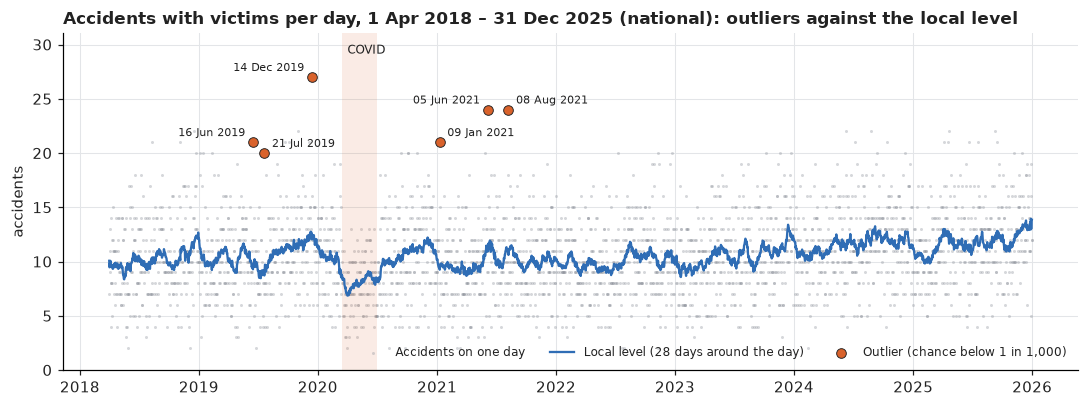

6 outlier days out of 2,832 (6 high, 0 low)


,day,holiday,accidents,local_level
2019-06-16,Sunday,,21,9.300
2019-07-21,Sunday,,20,8.700
2019-12-14,Saturday,,27,12.000
2021-01-09,Saturday,,21,9.200
2021-06-05,Saturday,,24,10.900
2021-08-08,Sunday,,24,10.600


In [16]:
# 3.4.1. Outliers in the whole selected period (1 Apr 2018 - 31 Dec 2025): each day against its local level
from scipy.stats import poisson
from features import get_brazil_holidays

def local_poisson_outliers(counts, window=28, p=0.001):
    """Flag the days whose count is very unlikely given the local level.
    Local level = the average of the 28 days around the day (14 before, 14 after; the day itself is left out).
    A day is an outlier if a count this high (or this low) has a chance below p = 1 in 1,000 under a Poisson distribution."""
    roll = counts.rolling(window + 1, center=True, min_periods=window // 2 + 1)
    local = (roll.sum() - counts) / (roll.count() - 1)
    return pd.DataFrame({"accidents": counts, "local_level": local,
                         "high": poisson.sf(counts - 1, local) < p,      # P(X >= count)
                         "low": poisson.cdf(counts, local) < p})        # P(X <= count)

HOLIDAYS = get_brazil_holidays(ERA_START.year, 2025)
national = local_poisson_outliers(daily1[ERA_START:"2025-12-31"])
national_flagged = national[national["high"] | national["low"]]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(national.index, national["accidents"], s=4, color=GREY, alpha=0.35, linewidths=0, label="Accidents on one day")
ax.plot(national.index, national["local_level"], color=BLUE, linewidth=1.5, label="Local level (28 days around the day)")
ax.scatter(national_flagged.index, national_flagged["accidents"], s=40, color=ORANGE, edgecolor=DARK, linewidths=0.6,
           zorder=3, label="Outlier (chance below 1 in 1,000)")
for k, (d, row) in enumerate(national_flagged.iterrows()):   # labels left and right in turn, so close dates do not overlap
    ax.annotate(f"{d:%d %b %Y}", (d, row["accidents"]), xytext=(-5 if k % 2 == 0 else 5, 4), textcoords="offset points",
                ha="right" if k % 2 == 0 else "left", fontsize=7)
ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-30"), color=ORANGE, alpha=0.12, linewidth=0)
ax.text(pd.Timestamp("2020-04-01"), national["accidents"].max() * 1.08, "COVID", fontsize=8)
ax.set(title="Accidents with victims per day, 1 Apr 2018 – 31 Dec 2025 (national): outliers against the local level",
       ylabel="accidents", ylim=(0, national["accidents"].max() * 1.15))
ax.legend(loc="lower right", fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

print(f"{len(national_flagged)} outlier days out of {len(national):,} "
      f"({national_flagged['high'].sum()} high, {national_flagged['low'].sum()} low)")
national_flagged.assign(day=national_flagged.index.day_name(),
                        holiday=[HOLIDAYS.get(d, "") for d in national_flagged.index],
                        local_level=national_flagged["local_level"].round(1))[["day", "holiday", "accidents", "local_level"]]

**Result:** 6 outlier days out of 2,832, all of them high (none low), and all on a Saturday or Sunday; none is a holiday. The most extreme is Saturday 14 Dec 2019: 27 accidents with victims, against a local level of 12. The COVID drop is not flagged: it was gradual, so the local level follows it. Section 5.1 repeats the test per region, on the target table.

#### 3.4.2. Boxplot per year

- **The box** holds the middle half of the days (from the 25th to the 75th percentile); the line inside is the median.
- **The whiskers** reach up to 1.5 × the height of the box beyond it. The days beyond the whiskers (grey dots) are the boxplot's outliers. The number above each box counts them.
- **Orange:** the outlier days of the local test (3.4.1), for comparison.

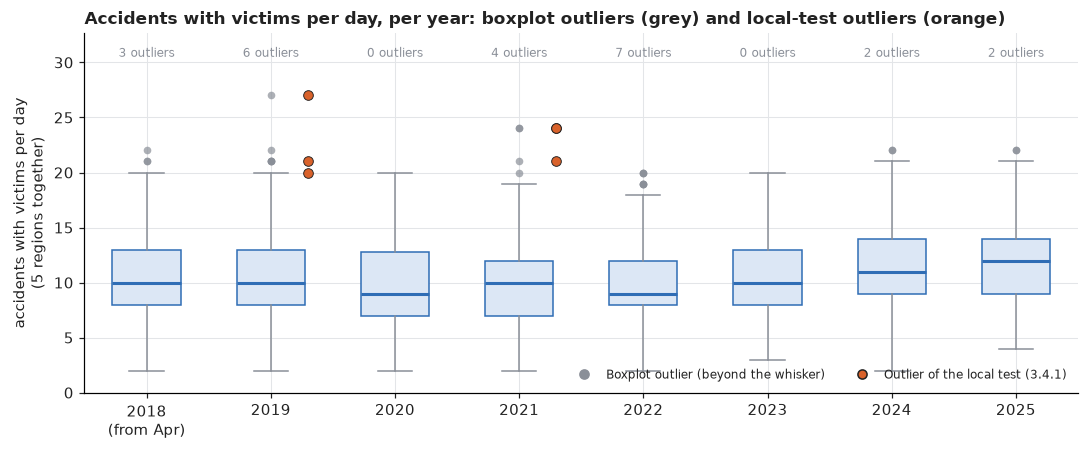

In [17]:
# 3.4.2. Boxplot of the daily counts per year (5 regions together), with the outliers of the local test (3.4.1)
from matplotlib.lines import Line2D

def boxplot_outliers(s):
    """Number of values beyond the whiskers (1.5 x the box height), the boxplot's own outlier rule."""
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s > q3 + 1.5 * (q3 - q1)) | (s < q1 - 1.5 * (q3 - q1))).sum())

by_year = [(y, g) for y, g in national.groupby(national.index.year)]
top = national["accidents"].max() * 1.12
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.boxplot([g["accidents"] for _, g in by_year], positions=range(len(by_year)), widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#DCE7F5", edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=GREY), capprops=dict(color=GREY),
           flierprops=dict(marker="o", markersize=5, markerfacecolor=GREY, markeredgecolor="none", alpha=0.7))
for k, (y, g) in enumerate(by_year):
    f = g[g["high"] | g["low"]]
    ax.scatter(np.full(len(f), k + 0.3), f["accidents"], s=40, color=ORANGE, edgecolor=DARK, linewidths=0.6, zorder=3)
    n = boxplot_outliers(g["accidents"])
    ax.text(k, top, f"{n} outlier{'s' if n != 1 else ''}", ha="center", va="bottom", fontsize=8, color=GREY)
ax.set_xticks(range(len(by_year)), [f"{y}\n(from Apr)" if y == ERA_START.year else str(y) for y, _ in by_year])
ax.set(ylim=(0, top * 1.08), ylabel="accidents with victims per day\n(5 regions together)",
       title="Accidents with victims per day, per year: boxplot outliers (grey) and local-test outliers (orange)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=GREY, label="Boxplot outlier (beyond the whisker)"),
                   Line2D([], [], marker="o", ls="", color=ORANGE, markeredgecolor=DARK, label="Outlier of the local test (3.4.1)")],
          loc="lower right", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Result**

| Year | Median per day | Middle half of the days | Boxplot outliers | Local-test outliers | Busiest day |
|---|---|---|---|---|---|
| 2018 (from Apr) | 10 | 8–13 | 3 | 0 | 22 |
| 2019 | 10 | 8–13 | 6 | 3 | 27 |
| 2020 | 9 | 7–13 | 0 | 0 | 20 |
| 2021 | 10 | 7–12 | 4 | 3 | 24 |
| 2022 | 9 | 8–12 | 7 | 0 | 20 |
| 2023 | 10 | 8–13 | 0 | 0 | 20 |
| 2024 | 11 | 9–14 | 2 | 0 | 22 |
| 2025 | 12 | 9–14 | 2 | 0 | 22 |

- **Every year looks alike:** a median of 9–12 accidents with victims per day, with the middle half of the days between 7 and 14. No year stands out; the level rises slowly from 2023 (median 10 in 2023, 12 in 2025).
- **The boxplot flags 24 days in almost 8 years**, at most 7 in a year, all of them high and just beyond the whisker (20–27 accidents). Only 6 of them are also outliers in the local test; the others are busy days in a busier period.
- **2020 has no outliers:** the COVID drop shows as a lower box (median 9), not as single extreme days.

--------
## 4. Region

In [18]:
# Region names (Portuguese -> English, as in the weather tables), the 94 reference cities
# and the functions that assign each accident to the region of its nearest city: see src/features.py
from features import REGION_EN, MAX_ANCHOR_KM, ANCHORS, anchors, haversine_km, assign_region

print(len(anchors), "reference cities:", anchors.region.value_counts().to_dict())

94 reference cities: {'Sudeste': 24, 'Nordeste': 21, 'Sul': 18, 'Centro-Oeste': 17, 'Norte': 14}


2017-2025 rows with coordinates: 43,763 | invalid coordinates removed: 3


points with no region (too far from every city): 0
points within 30 km of a regional border (could be on the wrong side): 1.3%


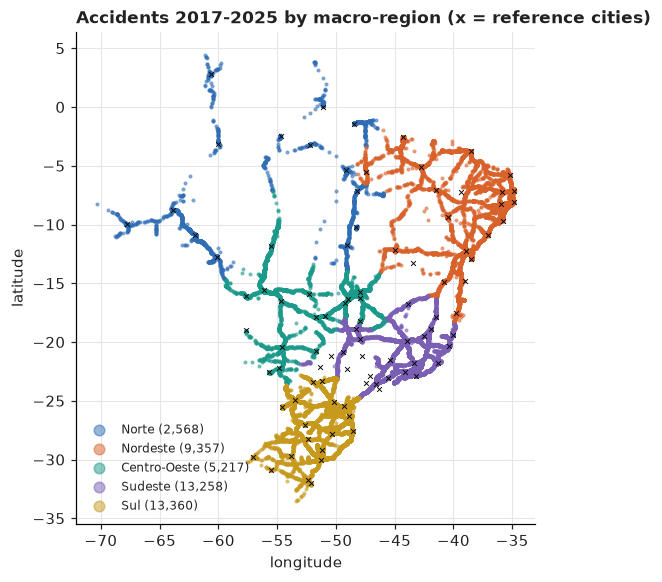

In [19]:
# Keep the modelling years that have coordinates, and drop the invalid coordinates (see section 2.2)
geo = raw[raw["date"] >= "2017-01-01"].dropna(subset=["latitude", "longitude"]).copy()
geo["valid_coord"] = geo["latitude"].between(-34, 6) & geo["longitude"].between(-74, -32)
print(f"2017-2025 rows with coordinates: {len(geo):,} | invalid coordinates removed: {(~geo.valid_coord).sum()}")
acc_region = geo[geo.valid_coord].copy()

acc_region["region"], acc_region["dist_km"], acc_region["border_gap_km"] = assign_region(
    acc_region["latitude"].values, acc_region["longitude"].values)
acc_region.loc[acc_region["dist_km"] > MAX_ANCHOR_KM, "region"] = np.nan
acc_region["region_en"] = acc_region["region"].map(REGION_EN)

print(f"points with no region (too far from every city): {acc_region.region.isna().sum()}")
print(f"points within 30 km of a regional border (could be on the wrong side): {(acc_region.border_gap_km < 30).mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 5.8))
for r in REGIONS:
    s = acc_region[acc_region.region == r]
    ax.scatter(s.longitude, s.latitude, s=3, color=REGION_COLORS[r], label=f"{r} ({len(s):,})", alpha=0.5)
ax.scatter(anchors.lon, anchors.lat, s=10, color="black", marker="x", linewidths=0.6)
ax.set(title="Accidents 2017-2025 by macro-region (x = reference cities)",
       xlabel="longitude", ylabel="latitude", aspect="equal")
ax.legend(markerscale=4, fontsize=8, loc="lower left")
plt.show()

Saved /Users/ivanacaridad/src/road_safety_machine_learning/data/processed/accidents_region.csv: 43,760 rows


,victim_accidents,fatal_%,per_day
region,,,
Norte,1750,13.371,0.618
Nordeste,6454,12.209,2.280
Centro-Oeste,3486,8.692,1.231
Sudeste,9314,6.571,3.290
Sul,8853,6.856,3.127


region,year,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
0,2018,4.900,14.800,8.600,21.400,21.700
1,2019,4.200,14.900,8.700,23.000,23.400
2,2020,4.200,15.000,8.500,21.600,19.300
3,2021,3.700,14.100,8.500,21.600,21.700
4,2022,4.600,15.300,8.100,21.200,21.000
5,2023,4.000,17.000,8.400,22.800,21.100
6,2024,4.500,18.300,9.200,25.300,23.600
7,2025,4.700,17.900,8.900,27.000,23.300


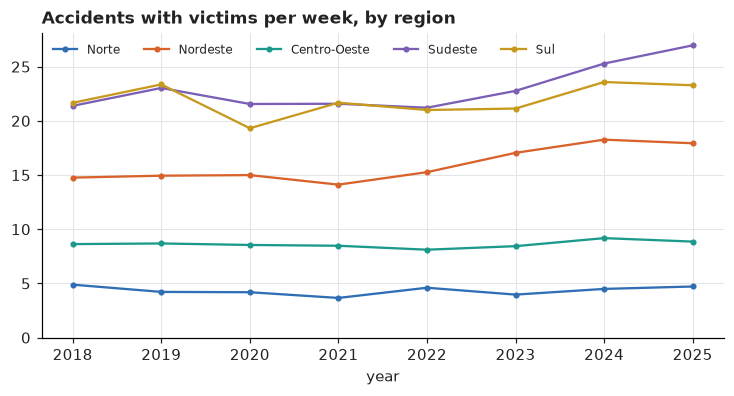

In [20]:
# Save a small table that colleagues can join to the calendar and to the weather (on region_en and date)
# filter by accident_classification >= 1 and 2
acc_region["is_victim"] = (acc_region["accident_classification"] >= 1).astype(int)
acc_region["is_fatal"] = (acc_region["accident_classification"] == 2).astype(int)

# filter and drop rows with missing region (too far from any reference city)
""" acc_region_out = acc_region.dropna(subset=["region"])[
    ["date", "region", "region_en", "latitude", "longitude", "accident_classification", "is_victim", "is_fatal"]]""" 
    
# replace the above with the following to include all road features and context columns + accidents_id
acc_region_out = acc_region.dropna(subset=["region"])[
    ["accident_id", "date", "region", "region_en", "latitude", "longitude",
     "time_of_day", "roadway_type", "area_type"]              # severity context (role table in 2.1)
    + ROAD_FEATURES                                           # all 13 road features
    + ["accident_classification", "is_victim", "is_fatal"]]

acc_region_out.to_csv(OUT / "accidents_region.csv", index=False)
print(f"Saved {OUT / 'accidents_region.csv'}: {len(acc_region_out):,} rows")

# Region summary (accidents with victims only, from the stable coding period)
# fatal_% = share of the victim accidents that had a death
v = acc_region_out[(acc_region_out.is_victim == 1) & (acc_region_out.date >= ERA_START)]
weeks = (pd.Timestamp("2025-12-31") - ERA_START).days / 7
summary = v.groupby("region").agg(victim_accidents=("is_victim", "size"), fatal_share=("is_fatal", "mean")).reindex(REGIONS)
summary["per_day"] = summary["victim_accidents"] / (weeks * 7)
summary["fatal_share"] = summary["fatal_share"] * 100
summary = summary.rename(columns={"fatal_share": "fatal_%"})
display(summary)

# Accidents with victims per week, by region and year
# Ivana: 2018 it is misleading, it starts on 1 April, so it is not a full year, but it is the first year of the dataset with stable coding. It has 39 weeks
# new 23/10/2026 -- Ivana
days_in_year = pd.Series(pd.date_range(ERA_START, "2025-12-31")).dt.year.value_counts()   # 2018 has only 275 days
per_week = (v.groupby([v.date.dt.year.rename("year"), "region"]).size().unstack()[REGIONS]
            .div(days_in_year / 7, axis=0))
display(per_week.round(1).reset_index()) 
# per_week = (v.assign(year=v.date.dt.year).groupby(["year", "region"]).size().unstack()[REGIONS] / 52)
fig, ax = plt.subplots()
for r in REGIONS:
    ax.plot(per_week.index, per_week[r], color=REGION_COLORS[r], marker="o", ms=3, label=r)
ax.set(title="Accidents with victims per week, by region", ylim=(0, None))
ax.legend(ncol=5, fontsize=8)
ax.set_xticks(per_week.index)
ax.set_xlabel("year")

plt.show()

**Reading**

- **Regions are very different in size.** Sudeste (3.3) and Sul (3.1) have about 3 accidents with victims per day, Nordeste 2.3, Centro-Oeste 1.2, and Norte only 0.6 (less than one a day). Because the counts are small, we predict a count and not a yes or no.
- **Fatal share is higher in Norte (13%) and Nordeste (12%)** than in Sudeste and Sul (about 7%). So region also tells us how serious the accidents are.
- **The trend is not the same in every region.** Per week, Sudeste went from 21 (2018) to 27 (2025), and Nordeste from 15 to 18. Norte, Centro-Oeste and Sul stayed roughly flat. A single national trend would miss this, so the model needs region-specific history features (section 6.3).
- **2018 is a partial year** (from 1 April, 39 weeks). The weekly rates divide each year by its own number of weeks, so 2018 is comparable with the full years.
- **The border error is small.** Only 1.3% of points are within 30 km of a regional border. No valid point was rejected for being too far from a city.
- **Limit:** the nearest city is only an approximation. Future work: use the official IBGE state borders, and move from 5 regions to 27 states.

**Decision:** region = region of the nearest reference city. We keep two names: `region` (Portuguese, used in this notebook) and `region_en` (English, the same names as in the weather tables), so colleagues can join on `region_en` and `date`.

**Saved file:** `accidents_region.csv` has one row per accident (43,760 rows, 2017–2025) with `accident_id` (to trace each row back to the raw data), the region, the severity context (`time_of_day`, `roadway_type`, `area_type`) and the 13 road features. It is the input for the target table in section 5; the models use the daily counts per region built there, not this file directly.


--------
## 5. Target table (not the training)

One row per **region per day**, from `ERA_START` to 2025-12-31, with the number of accidents with victims (class 1 or 2).

- Built from `accidents_region.csv` (section 4).
- Days without accidents are kept with a count of **0**.
- COVID days (2020-03-16 to 2020-06-30) are flagged, not deleted, so each model can decide how to treat them.

Building every region × day combination first is what keeps the days without accidents, with a count of 0. A plain groupby would drop them, and the model would learn that every day has at least one accident. That matters most for Norte, which has fewer than one accident with victims a day.

In [21]:
# The models need one row per region per day, with the number of accidents with victims. 
#  The models never see individual accidents, only those daily counts.
# Section 5: count accidents with victims per region per day; days without accidents = 0
victims_region = acc_region_out[(acc_region_out.is_victim == 1) & (acc_region_out.date >= ERA_START)]
days = pd.date_range(ERA_START, "2025-12-31", freq="D") #frequency daily 

target = (victims_region.groupby(["region", "date"]).size()
          .reindex(pd.MultiIndex.from_product([REGIONS, days], names=["region", "date"]), fill_value=0) #fill missing days with 0 accidents
          .rename("accidents").reset_index())
target["region_en"] = target["region"].map(REGION_EN)
target["is_covid"] = target["date"].between("2020-03-16", "2020-06-30").astype(int)
target


,region,date,accidents,region_en,is_covid
0,Norte,2018-04-01,0,North,0
1,Norte,2018-04-02,0,North,0
2,Norte,2018-04-03,0,North,0
3,Norte,2018-04-04,1,North,0
4,Norte,2018-04-05,1,North,0
...,...,...,...,...,...
14155,Sul,2025-12-27,5,South,0
14156,Sul,2025-12-28,1,South,0
14157,Sul,2025-12-29,4,South,0
14158,Sul,2025-12-30,3,South,0


Choice to make:
which days to train on. Our forecast only weekends and holidays, which are 908 of the 2,832 days. I'd suggest:

* Train on all days, with is_weekend and is_holiday as features. 
* That's three times more data, and weekdays still teach the model each region's level and trend.
* Evaluate only on weekends and holidays, because those are the days the planners use.

In [22]:
# check cell
# Checks: one row per region per day, no accidents lost, zero days kept
assert len(target) == len(REGIONS) * len(days)
assert target["accidents"].sum() == len(victims_region)

target.groupby("region")["accidents"].agg(
    avg_per_day="mean", variance="var",
    zero_days_pct=lambda s: (s == 0).mean() * 100, max="max").reindex(REGIONS).round(2)


,avg_per_day,variance,zero_days_pct,max
region,,,,
Norte,0.620,0.660,54.870,7
Nordeste,2.280,2.520,11.300,12
Centro-Oeste,1.230,1.270,29.840,6
Sudeste,3.290,3.610,4.100,12
Sul,3.130,3.340,4.200,11


* In Norte, more than half the days have 0 accidents, which is why the target has to be a count. Without the 0-filling, the model would think every day has at least one accident.
* Poisson fits these counts well. In a Poisson distribution the variance equals the average, and here it's only 5–10% higher in every region. That supports the GLM Poisson model and the Poisson settings for XGBoost and Random Forest. 

### 5.1. Outliers in the target table

The target table is the data the models learn from: accidents with victims per region per day, 1 Apr 2018 – 31 Dec 2025. The same test as in 3.4.1 is applied per region: each region-day against the region's own local level.

- **5.1.1:** the outlier days per region, on the daily counts, with the local level.
- **5.1.2:** three ways to call a day an outlier (the boxplot rule, a z-score above 3, and the local Poisson test), and how many days each one flags. `by_chance_at_most`: with a threshold of 1 in 1,000, chance alone produces at most about 1 outlier per 1,000 days, so about 2.8 per region.

### 5.1. Outliers per region

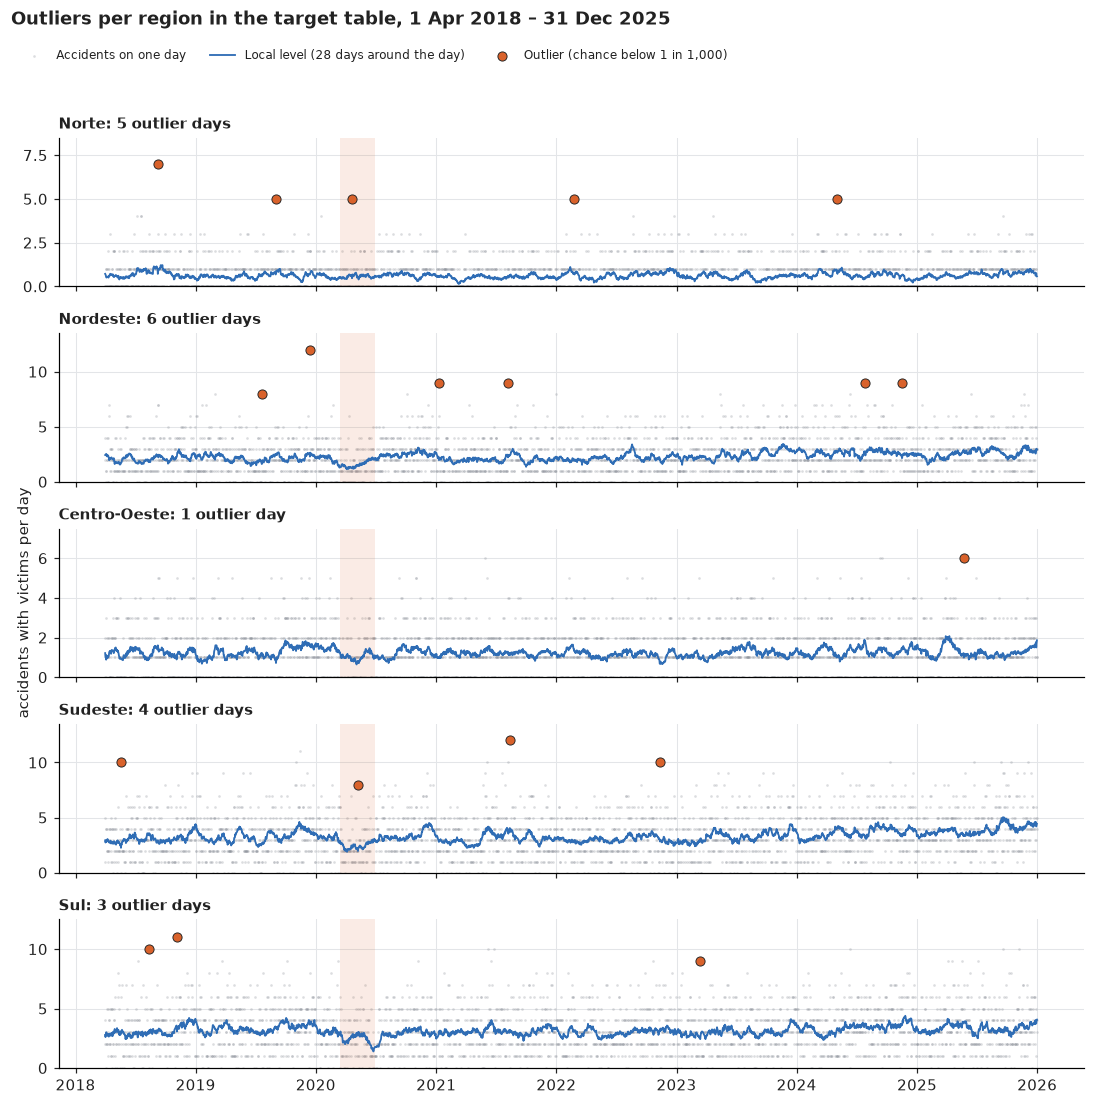

,region,date,day,holiday,accidents,local_level
0,Norte,2018-09-08,Saturday,,7,0.700
1,Norte,2019-09-01,Sunday,,5,0.700
2,Norte,2020-04-20,Monday,,5,0.500
3,Norte,2022-02-25,Friday,,5,0.700
4,Norte,2024-05-04,Saturday,,5,0.700
5,Nordeste,2019-07-21,Sunday,,8,1.600
6,Nordeste,2019-12-14,Saturday,,12,2.300
7,Nordeste,2021-01-09,Saturday,,9,2.000
8,Nordeste,2021-08-07,Saturday,,9,2.200
9,Nordeste,2024-07-28,Sunday,,9,2.400


In [23]:
# 5.1.1. Outliers per region in the target table: each region-day against its local level (same test as 3.4.1)
region_outliers = pd.concat({r: local_poisson_outliers(target[target["region"] == r].set_index("date")["accidents"])
                             for r in REGIONS}, names=["region"])

fig, axes = plt.subplots(len(REGIONS), 1, figsize=(10, 2.0 * len(REGIONS)), sharex=True)
for ax, r in zip(axes, REGIONS):
    d = region_outliers.loc[r]
    f = d[d["high"] | d["low"]]
    ax.scatter(d.index, d["accidents"], s=3, color=GREY, alpha=0.3, linewidths=0, label="Accidents on one day")
    ax.plot(d.index, d["local_level"], color=BLUE, linewidth=1.2, label="Local level (28 days around the day)")
    ax.scatter(f.index, f["accidents"], s=36, color=ORANGE, edgecolor=DARK, linewidths=0.6, zorder=3,
               label="Outlier (chance below 1 in 1,000)")
    ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-06-30"), color=ORANGE, alpha=0.12, linewidth=0)
    ax.set_title(f"{r}: {len(f)} outlier day{'s' if len(f) != 1 else ''}", loc="left", fontsize=10)
    ax.set_ylim(0, d["accidents"].max() + 1.5)
axes[len(REGIONS) // 2].set_ylabel("accidents with victims per day")
fig.suptitle("Outliers per region in the target table, 1 Apr 2018 – 31 Dec 2025", x=0.01, y=1.0, ha="left", fontweight="bold")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.01, 0.975), ncol=3, fontsize=8)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

flagged = region_outliers[region_outliers["high"] | region_outliers["low"]].reset_index()
flagged.assign(day=flagged["date"].dt.day_name(), holiday=flagged["date"].map(lambda d: HOLIDAYS.get(d, "")),
               local_level=flagged["local_level"].round(1))[["region", "date", "day", "holiday", "accidents", "local_level"]]

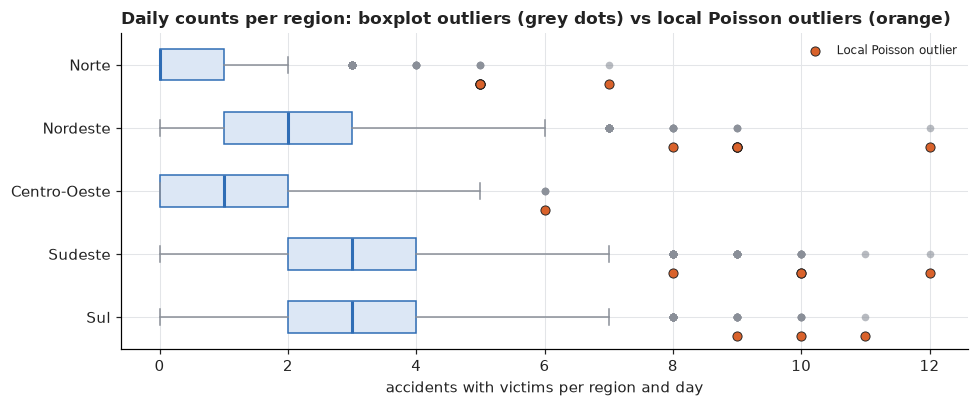

,days,avg_per_day,max_per_day,boxplot_rule,z_score_above_3,local_poisson,by_chance_at_most
Norte,2832,0.620,7.000,76,13,5,2.800
Nordeste,2832,2.280,12.000,41,13,6,2.800
Centro-Oeste,2832,1.230,6.000,4,30,1,2.800
Sudeste,2832,3.290,12.000,72,33,4,2.800
Sul,2832,3.130,11.000,45,19,3,2.800
Total,14160,NaN,NaN,238,108,19,14.000


In [24]:
# 5.1.2. Three ways to call a day an outlier, per region: the boxplot rule, the z-score and the local Poisson test
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot([target.loc[target["region"] == r, "accidents"] for r in REGIONS], vert=False, tick_labels=REGIONS,
           widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#DCE7F5", edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=GREY), capprops=dict(color=GREY),
           flierprops=dict(marker="o", markersize=5, markerfacecolor=GREY, markeredgecolor="none", alpha=0.6))
for k, r in enumerate(REGIONS, start=1):
    f = region_outliers.loc[r].query("high or low")
    ax.scatter(f["accidents"], np.full(len(f), k + 0.3), s=36, color=ORANGE, edgecolor=DARK, linewidths=0.6, zorder=3,
               label="Local Poisson outlier" if k == 1 else None)
ax.invert_yaxis()
ax.set(xlabel="accidents with victims per region and day",
       title="Daily counts per region: boxplot outliers (grey dots) vs local Poisson outliers (orange)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

def count_outliers(r):
    s = target.loc[target["region"] == r, "accidents"]
    q1, q3 = s.quantile([0.25, 0.75])
    z = (s - s.mean()) / s.std()
    d = region_outliers.loc[r]
    return {"days": len(s), "avg_per_day": round(s.mean(), 2), "max_per_day": s.max(),
            "boxplot_rule": int(((s > q3 + 1.5 * (q3 - q1)) | (s < q1 - 1.5 * (q3 - q1))).sum()),
            "z_score_above_3": int((z.abs() > 3).sum()),
            "local_poisson": int((d["high"] | d["low"]).sum()),
            "by_chance_at_most": round(len(s) * 0.001, 1)}   # p = 0.001 per day: what chance alone can produce

comparison = pd.DataFrame({r: count_outliers(r) for r in REGIONS}).T
comparison.loc["Total"] = comparison.sum()
comparison.loc["Total", ["avg_per_day", "max_per_day"]] = np.nan
comparison.astype({c: "int64" for c in ["days", "boxplot_rule", "z_score_above_3", "local_poisson"]})

**Result and decision**

| Region | Average per day | Boxplot rule | z-score above 3 | Local Poisson test | By chance alone, at most |
|---|---|---|---|---|---|
| Norte | 0.62 | 76 | 13 | 5 | 2.8 |
| Nordeste | 2.28 | 41 | 13 | 6 | 2.8 |
| Centro-Oeste | 1.23 | 4 | 30 | 1 | 2.8 |
| Sudeste | 3.29 | 72 | 33 | 4 | 2.8 |
| Sul | 3.13 | 45 | 19 | 3 | 2.8 |
| **Total** | | **238** | **108** | **19** | **14** |

- **The boxplot rule and the z-score flag 238 and 108 region-days, but most of them are normal busy days.** With skewed counts and a small average, 3 accidents in a day in Norte, or 8 in Sudeste, is uncommon but not unusual.
- **The local Poisson test flags 19 of 14,160 region-days (0.13%)**, close to the 14 that chance alone would produce. 12 of the 19 are Saturdays or Sundays, the busier days; none is a holiday; 2 fall in the COVID period, which is left out of training anyway.
- **No day is unusually low:** the days with 0 accidents are normal for counts this small.
- **Decision: keep all days.** There are no data errors to remove: the high days are real accidents on busy days, and the models are built for them (Poisson loss, day-of-week and weekend features). Removing them would make the forecast too low on exactly the days the planners need.

### 5.2. Boxplot per region and day type

The models forecast weekends and holidays, so here the boxplots are split by day type:

- **weekday:** Monday to Friday;
- **weekend:** Saturday and Sunday;
- **holiday:** national holidays, Carnival and Corpus Christi (a holiday on a weekend counts as a holiday).

Each box has its own whiskers, so a busy weekend is compared with other weekends, not with weekdays.

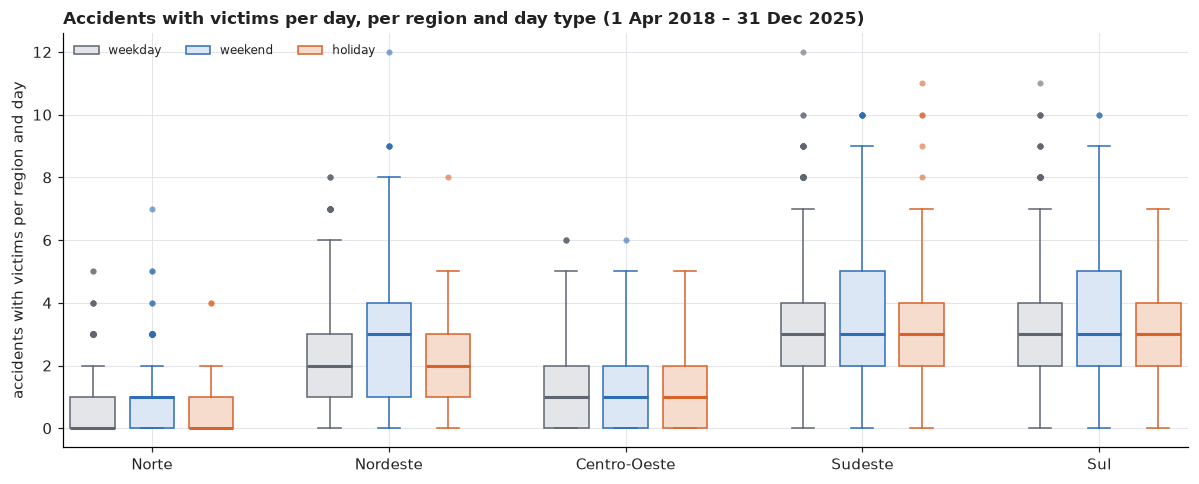

avg_per_day                 boxplot_outliers                          avg_per_day
day_type         weekday weekend holiday          weekday weekend holiday weekend_vs_weekday_%
region                                                                                        
Norte              0.570   0.750   0.500               38      36       2               29.980
Nordeste           2.140   2.680   1.940               21       5       1               25.130
Centro-Oeste       1.160   1.390   1.310                3       1       0               19.340
Sudeste            3.160   3.600   3.340               42       6       5               13.810
Sul                3.000   3.420   3.150               26       2       0               13.890

In [25]:
# 5.1.3. Boxplot per region and day type (weekday, weekend, holiday)
from matplotlib.patches import Patch

DAY_TYPES = {"weekday": ("#E3E5E8", "#5F6670"), "weekend": ("#DCE7F5", BLUE), "holiday": ("#F6DCCD", ORANGE)}   # fill, line
target_dt = target.assign(day_type=np.select([target["date"].isin(HOLIDAYS.index), target["date"].dt.dayofweek >= 5],
                                             ["holiday", "weekend"], "weekday"))

fig, ax = plt.subplots(figsize=(11, 4.5))
for j, (day_type, (face, line)) in enumerate(DAY_TYPES.items()):
    data = [target_dt.loc[(target_dt["region"] == r) & (target_dt["day_type"] == day_type), "accidents"] for r in REGIONS]
    ax.boxplot(data, positions=np.arange(len(REGIONS)) * 4 + j, widths=0.75, patch_artist=True,
               boxprops=dict(facecolor=face, edgecolor=line), medianprops=dict(color=line, linewidth=2),
               whiskerprops=dict(color=line), capprops=dict(color=line),
               flierprops=dict(marker="o", markersize=4, markerfacecolor=line, markeredgecolor="none", alpha=0.6))
ax.set_xticks(np.arange(len(REGIONS)) * 4 + 1, REGIONS)
ax.set(ylabel="accidents with victims per region and day",
       title="Accidents with victims per day, per region and day type (1 Apr 2018 – 31 Dec 2025)")
ax.legend(handles=[Patch(facecolor=f, edgecolor=l, label=t) for t, (f, l) in DAY_TYPES.items()], loc="upper left", ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

g = target_dt.groupby(["region", "day_type"])["accidents"]
day_type_table = pd.concat({"avg_per_day": g.mean().unstack()[list(DAY_TYPES)],
                            "boxplot_outliers": g.apply(boxplot_outliers).unstack()[list(DAY_TYPES)]}, axis=1).reindex(REGIONS)
day_type_table[("avg_per_day", "weekend_vs_weekday_%")] = 100 * (day_type_table[("avg_per_day", "weekend")]
                                                                 / day_type_table[("avg_per_day", "weekday")] - 1)
day_type_table.round(2)

**Result**

| Region | Average per weekday | Average per weekend day | Weekend vs weekday | Average per holiday | Boxplot outliers (weekday / weekend / holiday) |
|---|---|---|---|---|---|
| Norte | 0.57 | 0.75 | +30% | 0.50 | 38 / 36 / 2 |
| Nordeste | 2.14 | 2.68 | +25% | 1.94 | 21 / 5 / 1 |
| Centro-Oeste | 1.16 | 1.39 | +19% | 1.31 | 3 / 1 / 0 |
| Sudeste | 3.16 | 3.60 | +14% | 3.34 | 42 / 6 / 5 |
| Sul | 3.00 | 3.42 | +14% | 3.15 | 26 / 2 / 0 |

- **Weekends are busier in every region**, by 14–30% per day, and their boxes reach higher (the 75th percentile is 5 accidents instead of 4 in Sudeste and Sul).
- **Split by day type, the boxplot flags 188 region-days instead of 238** (one box per region, 5.1.2). Many of the high days were only unusual compared with weekdays.
- **Most of the remaining boxplot outliers are weekdays** (130 of 188), mainly in Norte, Sudeste and Sul. They are days with 4–5 accidents in Norte, or 8 or more in Sudeste and Sul: uncommon, but within the normal spread of counts this small.
- **Holidays look like normal days:** their average is close to the weekdays', with only 8 boxplot outliers in total.
- **Same conclusion as 5.1:** the extreme values are the normal spread of the counts, higher on weekends. Nothing needs to be removed. The weekend effect is why the day of week and `is_weekend` are model features.

In [26]:
# make a copy of the target table to add the day_type column, which is used in the analysis of holidays and weekends
target_copy = target.copy()

--------
## 6. Feature engineering

### 6.1. Holiday and weekend calendar

The model forecasts weekends and holidays, so we need a calendar that marks them. We build one table with **one row per day**, from 2017 to 2026 (the modelling years plus the forecast year).

In [27]:
# The holiday and calendar functions are in src/features.py
from features import SKIP_HOLIDAYS, get_brazil_holidays, build_calendar

CAL_START, CAL_END = "2017-01-01", "2026-12-31"   # modelling years + the forecast year

calendar = build_calendar(CAL_START, CAL_END)
calendar.to_csv(OUT / "holidays_calendar.csv", index=False)
print(f"Saved {OUT / 'holidays_calendar.csv'}: {calendar.shape[0]:,} rows x {calendar.shape[1]} columns")
calendar.head(10)

Saved /Users/ivanacaridad/src/road_safety_machine_learning/data/processed/holidays_calendar.csv: 3,652 rows x 15 columns


,date,year,quarter,month,day,day_of_week,is_weekend,holiday_name,is_holiday,days_to_holiday,days_after_holiday,is_holiday_window,is_bridge_day,is_long_weekend,is_school_vacation
0,2017-01-01,2017,1,1,1,Sunday,1,Confraternização Universal,1,0,0,1,0,0,1
1,2017-01-02,2017,1,1,2,Monday,0,NaN,0,<NA>,1,1,0,0,1
2,2017-01-03,2017,1,1,3,Tuesday,0,NaN,0,<NA>,2,1,0,0,1
3,2017-01-04,2017,1,1,4,Wednesday,0,NaN,0,<NA>,3,1,0,0,1
4,2017-01-05,2017,1,1,5,Thursday,0,NaN,0,<NA>,<NA>,0,0,0,1
5,2017-01-06,2017,1,1,6,Friday,0,NaN,0,<NA>,<NA>,0,0,0,1
6,2017-01-07,2017,1,1,7,Saturday,1,NaN,0,<NA>,<NA>,0,0,0,1
7,2017-01-08,2017,1,1,8,Sunday,1,NaN,0,<NA>,<NA>,0,0,0,1
8,2017-01-09,2017,1,1,9,Monday,0,NaN,0,<NA>,<NA>,0,0,0,1
9,2017-01-10,2017,1,1,10,Tuesday,0,NaN,0,<NA>,<NA>,0,0,0,1


In [28]:
# Quick checks on the calendar
assert calendar["date"].is_unique, "duplicate dates"
assert len(calendar) == (pd.Timestamp(CAL_END) - pd.Timestamp(CAL_START)).days + 1, "missing dates"

per_year = calendar.groupby("year").agg(
    weekend_days=("is_weekend", "sum"),
    holidays=("is_holiday", "sum"),
    holidays_on_weekdays=("is_holiday", lambda s: int(((s == 1) & (calendar.loc[s.index, "is_weekend"] == 0)).sum())),
    holiday_window_days=("is_holiday_window", "sum"),
    long_weekend_days=("is_long_weekend", "sum"),
)
display(per_year.T)

# Example: Carnival 2024. The window columns should count down to the holiday and up after it.
calendar.loc[calendar["date"].between("2024-02-07", "2024-02-18"),
             ["date", "day_of_week", "holiday_name", "is_holiday", "days_to_holiday",
              "days_after_holiday", "is_holiday_window", "is_long_weekend"]]

year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
weekend_days,105,104,104,104,104,105,105,104,104,104
holidays,16,16,16,16,16,16,16,17,17,17
holidays_on_weekdays,12,14,12,15,14,11,12,13,13,16
holiday_window_days,85,85,80,85,85,84,85,90,86,90
long_weekend_days,35,37,28,34,36,25,35,28,32,39


,date,day_of_week,holiday_name,is_holiday,days_to_holiday,days_after_holiday,is_holiday_window,is_long_weekend
2593,2024-02-07,Wednesday,NaN,0,<NA>,<NA>,0,0
2594,2024-02-08,Thursday,NaN,0,<NA>,<NA>,0,0
2595,2024-02-09,Friday,NaN,0,3,<NA>,1,0
2596,2024-02-10,Saturday,NaN,0,2,<NA>,1,1
2597,2024-02-11,Sunday,NaN,0,1,<NA>,1,1
2598,2024-02-12,Monday,Carnaval,1,0,0,1,1
2599,2024-02-13,Tuesday,Carnaval,1,0,0,1,1
2600,2024-02-14,Wednesday,Quarta-feira de Cinzas,1,0,0,1,1
2601,2024-02-15,Thursday,NaN,0,<NA>,1,1,0
2602,2024-02-16,Friday,NaN,0,<NA>,2,1,0


It looks good

### 6.1.1. Do weekends and holidays have more accidents?

Before we trust the calendar, we check if it explains the accident counts. We count the accidents with injuries or deaths per day (the target) and compare the day types.

,days,avg_per_day,vs_normal_weekday_%
day_type,,,
Normal weekday,1496,10.060,0.000
Day near a holiday,355,10.456,3.938
Weekend,779,11.954,18.823
Holiday (on a weekday),95,9.937,-1.226


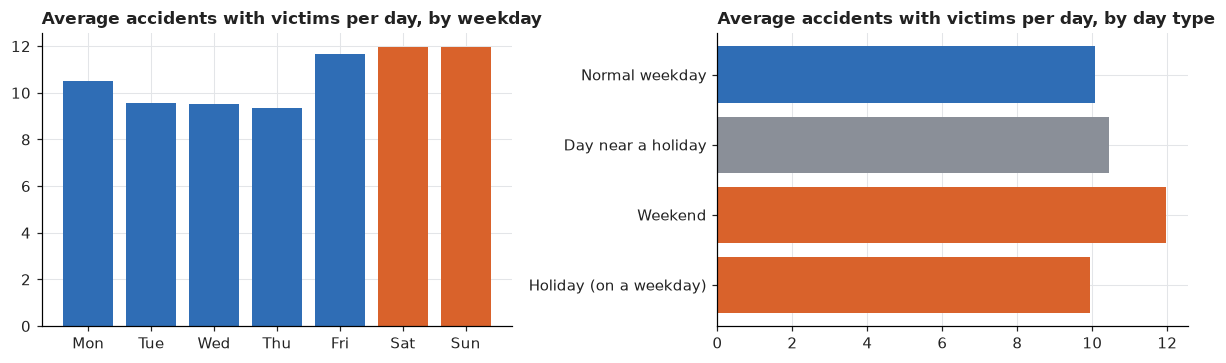

In [29]:
# Target: accidents with injury (1) or death (2). Class 0 is excluded.
victims = raw[(raw["accident_classification"] >= 1) & (raw["date"] >= ERA_START)]

# One row per day. Days with no accident are kept with a count of 0.
all_days = pd.date_range(ERA_START, "2025-12-31", freq="D")
daily = (victims.groupby("date").size().reindex(all_days, fill_value=0)
         .rename("accidents").rename_axis("date").reset_index())
daily = daily.merge(calendar, on="date", how="left")
daily = daily[~daily["date"].between("2020-03-16", "2020-06-30")]     # remove COVID

# One label per day. The order matters: the first rule that is true wins.
daily["day_type"] = np.select(
    [(daily.is_holiday == 1) & (daily.is_weekend == 0),
     daily.is_weekend == 1,
     daily.is_holiday_window == 1],
    ["Holiday (on a weekday)", "Weekend", "Day near a holiday"],
    default="Normal weekday")

by_type = daily.groupby("day_type")["accidents"].agg(days="size", avg_per_day="mean") # avg_per_day = mean accidents per day of that type
base = by_type.loc["Normal weekday", "avg_per_day"] # base value for comparison
by_type["vs_normal_weekday_%"] = (by_type["avg_per_day"] / base - 1) * 100 # vs_normal_weekday_% is the percentage difference compared to normal weekdays
by_type = by_type.loc[["Normal weekday", "Day near a holiday", "Weekend", "Holiday (on a weekday)"]]
display(by_type)

week_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = daily.groupby("day_of_week")["accidents"].mean().reindex(week_order)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(by_day.index.str[:3], by_day.values, color=[BLUE] * 5 + [ORANGE] * 2)
axes[0].set(title="Average accidents with victims per day, by weekday", ylim=(0, None))
axes[1].barh(by_type.index[::-1], by_type["avg_per_day"][::-1], color=[ORANGE, ORANGE, GREY, BLUE])
axes[1].set(title="Average accidents with victims per day, by day type", xlim=(0, None))
plt.tight_layout(); plt.show()

**Reading**

- **Weekends** have about 19% more accidents with victims than a normal weekday (about 12.0 against 10.1 per day). So `is_weekend` is a useful input.
- **Days near a holiday** are only about 4% above a normal weekday. This is a small effect.
- **Holidays on a weekday** have the same average as a normal weekday. But this average hides big differences between holidays. The next table shows them.

In [30]:
# Holiday effect by holiday name: average accidents on the holiday vs normal weekdays
# (national numbers per day; a holiday on a weekend is left out, because weekends are higher anyway)
hol_days = daily[(daily.is_holiday == 1) & (daily.is_weekend == 0)]
by_holiday = hol_days.groupby("holiday_name")["accidents"].agg(times="size", avg_per_day="mean")
by_holiday["vs_normal_weekday_%"] = (by_holiday["avg_per_day"] / base - 1) * 100
by_holiday.sort_values("vs_normal_weekday_%", ascending=False)

,times,avg_per_day,vs_normal_weekday_%
holiday_name,,,
Tiradentes,4,13.500,34.193
Natal,6,12.500,24.252
Proclamação da República,6,12.000,19.282
Confraternização Universal,5,11.200,11.330
Dia do Trabalhador,5,11.000,9.342
Independência do Brasil,5,11.000,9.342
Dia Nacional de Zumbi e da Consciência Negra,2,10.500,4.372
Dia do Servidor Público,6,10.167,1.059
Véspera de Natal,6,10.167,1.059


**Reading**

- Holidays are not all the same. Some are **higher** than a normal weekday: Tiradentes (+34%), Christmas (+24%) and Republic Day (+19%).
- Others are **lower**: Carnival (-15%), Good Friday, Corpus Christi, Our Lady of Aparecida and All Souls' Day (-12% to -20%).
- Each holiday has only 2 to 14 days in the data, so the numbers are noisy. We use them as a hint, not as proof.

**Decision:** we keep `holiday_name` and the window columns in the calendar, so the model can learn a different effect for each holiday.

### 6.2. Weather and climate per region

The forecast is made **1 month before the quarter starts**, so the actual weather on a forecast day is **not known** at that time. Using it would be data leakage. We use the **usual weather (climate)** instead:

1. Download daily weather from the Open-Meteo archive API for the reference cities in `ANCHORS` (section 4).
2. Average it per region per day.
3. Summarise it per region and month: average rain, share of rainy days, average temperature.
4. Calculate the summary **from the training years only**, then join it on `region_en` and month.

**Decision**

Leakage: The climate is calculated from 2017–2023, but our backtest predicts quarters inside that period. When the model forecasts, say, 2021, the climate would already include weather from 2021–2023. The clean fix is to calculate it from the 10 years before our modelling period (April 2008 to March 2018). The archive goes back far enough, and those years never overlap with any training or test day.

In [31]:
import time
import requests
import requests_cache

# Persistent cache: successful responses are reused across notebook runs.
session = requests_cache.CachedSession(
    str(ROOT / "weather_cache"),
    expire_after=-1,
)

BASE_URL = "https://archive-api.open-meteo.com/v1/archive"

DAILY_VARIABLES = [
    "precipitation_sum",
    "temperature_2m_max",
    "relative_humidity_2m_min",
]

def get_daily_weather(lat, lon, start_date, end_date, retries=3):
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start_date,
        "end_date": end_date,
        "daily": ",".join(DAILY_VARIABLES),
        "timezone": "America/Sao_Paulo",
    }

    for attempt in range(retries + 1):
        try:
            response = session.get(
                BASE_URL,
                params=params,
                timeout=60,
            )

            # Do not repeatedly retry an hourly quota error.
            if response.status_code == 429:
                try:
                    detail = response.json().get("reason", response.text)
                except ValueError:
                    detail = response.text

                if "minutely" not in str(detail).lower():   # hourly or daily limit: waiting a minute won't help
                    raise RuntimeError(
                        f"Open-Meteo request limit reached: {detail} "
                        "Successful downloads are cached. Rerun this cell after the limit resets."
                    )
                if attempt == retries:
                    response.raise_for_status()
                print("(minute limit, waiting 65 s)", end=" ")
                time.sleep(65)                                # the per-minute limit resets after a minute
                continue

            response.raise_for_status()
            if not response.from_cache:
                time.sleep(5)                                 # pace new downloads; cached cities are instant
            payload = response.json()

            if payload.get("error"):
                raise RuntimeError(payload.get("reason", payload["error"]))

            daily = payload.get("daily", {})
            if not daily.get("time"):
                raise RuntimeError(
                    f"No daily weather data returned for ({lat}, {lon})."
                )

            return pd.DataFrame({
                "date": pd.to_datetime(daily["time"]),
                "precipitation_sum": daily["precipitation_sum"],
                "temperature_2m_max": daily["temperature_2m_max"],
                "relative_humidity_2m_min": daily[
                    "relative_humidity_2m_min"
                ],
            })

        except RuntimeError:
            raise
        except (requests.RequestException, ValueError) as exc:
            if attempt == retries:
                raise RuntimeError(
                    f"Weather download failed for ({lat}, {lon}): {exc}"
                ) from exc
            time.sleep(2 ** attempt)

    raise RuntimeError(f"Weather download failed for ({lat}, {lon}).")


# Climate period: the 10 years BEFORE the modelling period, so no training or test day is used
CLIMATE_START, CLIMATE_END = "2008-04-01", "2018-03-31"

# Download each city's daily weather. Cached responses require no new API call.
weather_parts = []

for i, a in enumerate(anchors.itertuples(), start=1):
    print(f"[{i}/{len(anchors)}] {a.city}", end=" ")

    city_weather = get_daily_weather(
        a.lat,
        a.lon,
        CLIMATE_START,
        CLIMATE_END,
    )

    city_weather = city_weather.assign(city=a.city, region=a.region)
    weather_parts.append(city_weather)

    print(f"— {len(city_weather):,} daily records")

weather = pd.concat(weather_parts, ignore_index=True)

print("\nWeather download complete.")
print(f"Cities: {weather['city'].nunique()}")
print(f"Rows: {len(weather):,}")
print(f"Date range: {weather['date'].min().date()} to "
      f"{weather['date'].max().date()}")


[1/94] Porto Velho — 3,652 daily records
[2/94] Ji-Parana — 3,652 daily records
[3/94] Vilhena — 3,652 daily records
[4/94] Rio Branco — 3,652 daily records
[5/94] Manaus — 3,652 daily records
[6/94] Boa Vista — 3,652 daily records
[7/94] Macapa — 3,652 daily records
[8/94] Belem — 3,652 daily records
[9/94] Santarem — 3,652 daily records
[10/94] Maraba — 3,652 daily records
[11/94] Palmas — 3,652 daily records
[12/94] Araguaina — 3,652 daily records
[13/94] Gurupi — 3,652 daily records
[14/94] Altamira — 3,652 daily records
[15/94] Sao Luis — 3,652 daily records
[16/94] Imperatriz — 3,652 daily records
[17/94] Teresina — 3,652 daily records
[18/94] Fortaleza — 3,652 daily records
[19/94] Juazeiro do Norte — 3,652 daily records
[20/94] Natal — 3,652 daily records
[21/94] Joao Pessoa — 3,652 daily records
[22/94] Campina Grande — 3,652 daily records
[23/94] Recife — 3,652 daily records
[24/94] Petrolina — 3,652 daily records
[25/94] Caruaru — 3,652 daily records
[26/94] Maceio — 3,652 d

In [32]:
# climate calculations: monthly probabilities of rain, heavy rain, and fire weather
w = weather.assign(month=weather.date.dt.month,
                   rain_day=weather.precipitation_sum >= 1,         # at least 1 mm
                   heavy_rain_day=weather.precipitation_sum >= 20,  # at least 20 mm
                   # fire_weather_day is defined as a day that is dry, hot, and has very low humidity. The thresholds are:
                   # precipitation_sum < 1 mm (dry)
                   # relative_humidity_2m_min < 30% (very low humidity)
                   # temperature_2m_max >= 30°C (hot)
                   fire_weather_day=(weather.precipitation_sum < 1)          # dry
                                    & (weather.relative_humidity_2m_min < 30) # very low humidity
                                    & (weather.temperature_2m_max >= 30))     # hot

climate = (w.groupby(["region", "month"])
             .agg(rain_day_prob=("rain_day", "mean"),
                  heavy_rain_prob=("heavy_rain_day", "mean"),
                  avg_daily_precip=("precipitation_sum", "mean"),
                  avg_temp_max=("temperature_2m_max", "mean"),
                  avg_humidity_min=("relative_humidity_2m_min", "mean"),
                  fire_weather_prob=("fire_weather_day", "mean"))
             .reset_index())

# Wildfire season = months where at least 1 day in 3 has fire weather in that region
climate["wildfire_season"] = (climate["fire_weather_prob"] >= 1/3).astype(int)
climate["region_en"] = climate["region"].map(REGION_EN)
climate.to_csv(OUT / "climate_features.csv", index=False)

# Join to the target table (one row per region per day). New name, so re-running this cell is safe
target_climate = target.assign(month=target.date.dt.month).merge(
    climate.drop(columns="region_en"), on=["region", "month"], how="left")
assert target_climate["rain_day_prob"].notna().all(), "a region/month has no climate"
climate

,region,month,rain_day_prob,heavy_rain_prob,avg_daily_precip,avg_temp_max,avg_humidity_min,fire_weather_prob,wildfire_season,region_en
0,Centro-Oeste,1,0.716,0.084,7.361,28.982,60.917,0.005,0,Centre-West
1,Centro-Oeste,2,0.713,0.065,6.738,29.119,60.715,0.002,0,Centre-West
2,Centro-Oeste,3,0.693,0.047,5.912,28.869,61.867,0.000,0,Centre-West
3,Centro-Oeste,4,0.405,0.018,2.944,28.555,56.472,0.003,0,Centre-West
4,Centro-Oeste,5,0.171,0.011,1.253,27.463,50.380,0.007,0,Centre-West
5,Centro-Oeste,6,0.095,0.008,0.761,27.013,45.786,0.029,0,Centre-West
6,Centro-Oeste,7,0.057,0.006,0.490,27.657,37.382,0.145,0,Centre-West
7,Centro-Oeste,8,0.062,0.005,0.542,30.048,30.508,0.393,1,Centre-West
8,Centro-Oeste,9,0.179,0.012,1.360,31.927,32.500,0.441,1,Centre-West
9,Centro-Oeste,10,0.470,0.035,3.769,31.311,44.658,0.158,0,Centre-West


**Climate table (`climate`, saved as `climate_features.csv`)**

One row per **region and month** (5 regions × 12 months = 60 rows). It describes the **usual weather** in each region in each month, not the weather on a specific day.

- **Source:** daily weather from the Open-Meteo historical archive for the 94 reference cities in `anchors`, averaged per region.
- **Period:** April 2008 to March 2018, the 10 years *before* the modelling period. No training or test day is used, so there is no leakage.
- **Why not the actual weather?** The forecast is made 1 month before the quarter starts, when nobody knows whether it will rain on a given day. The usual weather for the month *is* known in advance.

| Column | Meaning |
|---|---|
| `rain_day_prob` | share of days with at least 1 mm of rain |
| `heavy_rain_prob` | share of days with at least 20 mm of rain |
| `avg_daily_precip` | average rain per day (mm) |
| `avg_temp_max` | average daily maximum temperature (°C) |
| `avg_humidity_min` | average daily minimum air humidity (%) |
| `fire_weather_prob` | share of "fire-weather" days: no rain (< 1 mm), hot (≥ 30 °C) and very dry air (humidity < 30%) |
| `wildfire_season` | 1 if at least 1 day in 3 has fire weather (`fire_weather_prob` ≥ 1/3) |
| `region_en` | English region name, for joins with teammates' tables |

**Reading**

- **The regions have very different seasons.** Centro-Oeste and Sudeste have rainy summers (rain on about 70% of days from November to March in Centro-Oeste) and very dry winters (6% in July and August). Norte is wettest from January to April (about 85% of days). The Nordeste rains most from February to May and is driest from September to November. In the Sul, rain is spread over the whole year (29–58% of days) and winters are cool (average maximum about 18 °C in June).
- **Heavy rain is most common in Norte from January to March** (about 1 day in 10) and in the Sul all year round (5–9% of days).
- **Fire weather peaks from August to October.** It is highest in Centro-Oeste (39% of days in August, 44% in September), followed by Norte (28% in August) and Nordeste (27% in September). It almost never happens in the Sul.
- **`wildfire_season` only marks August and September in Centro-Oeste.** Norte (28%) and Nordeste (27%) stay just below the 1-in-3 threshold, although both have a known burning season. The models therefore use `fire_weather_prob`, which keeps this information; `wildfire_season` is only a simple label for charts.

**Limits**

- Every city counts the same in its region's average, whatever its traffic.
- The climate is the same every year, so it cannot capture an unusually wet or dry year (for example, El Niño).

**Use:** joined to the target table on `region` and month, giving `target_climate` (one row per region per day).

In [33]:
# Which months does each region count as wildfire season? (expect roughly Aug-Oct in Centro-Oeste, none in Sul)
climate.pivot(index="region", columns="month", values="fire_weather_prob").reindex(REGIONS).round(2)


month,1,2,3,4,5,6,7,8,9,10,11,12
region,,,,,,,,,,,,
Norte,0.000,0.000,0.000,0.000,0.010,0.030,0.150,0.280,0.170,0.050,0.000,0.000
Nordeste,0.050,0.030,0.030,0.030,0.030,0.050,0.110,0.220,0.270,0.210,0.130,0.080
Centro-Oeste,0.000,0.000,0.000,0.000,0.010,0.030,0.150,0.390,0.440,0.160,0.010,0.000
Sudeste,0.020,0.020,0.000,0.000,0.000,0.000,0.010,0.100,0.220,0.110,0.020,0.010
Sul,0.010,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.030,0.000,0.000,0.010


### 6.3. History features

Each quarter is forecast 1 month before it starts (`LEAD_MONTHS`), so the history features only use days **before that cutoff**. They are calculated once per region and quarter (5 regions × 31 quarters = 155 rows) and are the same for every day of that quarter.

| Feature | Meaning |
|---|---|
| `hist_avg_91d` | average accidents with victims per day in the last 91 days before the cutoff |
| `hist_avg_365d` | the same over the last 365 days |
| `hist_dayoff_avg_365d` | the same over the last 365 days, but only weekends and holidays (the days we forecast) |
| `hist_same_q_last_year` | average per day in the same quarter one year earlier (seasonality) |
| `hist_trend` | `hist_avg_91d` / `hist_avg_365d`: above 1 means the last quarter was above the yearly level |

**Rules**

- **Only data from `ERA_START` (April 2018).** The severity coding changed then: the share of accidents with victims jumps from about 65% to about 80%, so earlier counts are not comparable.
- **COVID days are left out** of the averages, so they do not pull the history down.
- A window with **fewer than 28 usable days** gets no value (empty).
- The code **checks that no window reaches past the cutoff**, so no information from the forecast quarter leaks in.

**Consequences** & **limitations**

- The first quarters have no complete history. All five features are available from **2019 Q3** (24 of 31 quarters).
- Two gaps come from COVID: `hist_avg_91d` for 2020 Q3 (its window is almost all COVID) and `hist_same_q_last_year` for 2021 Q2 (2020 Q2 was entirely COVID).
- XGBoost and Random Forest handle empty values. The GLM does not: we will need train it on the rows with complete history, or fill the gaps.

In [34]:
# 6.3 History features: what each region's daily counts looked like at the forecast cutoff.
# Each quarter is forecast 1 month before it starts (LEAD_MONTHS), so only days BEFORE that cutoff are used.
# Only data from ERA_START is used: the data is incomplete before April 2018, so earlier counts are not comparable.
# COVID days are left out of the averages, so they do not pull the history down. (COVIT OUT) 
# For GLM models, the history needs to be complete, it does not handle NaN value well**

hist_days = target.merge(calendar[["date", "is_weekend", "is_holiday"]], on="date", how="left") #join the target table with calendar
hist_days = hist_days[hist_days["is_covid"] == 0].copy()                                        # filter out covid days
hist_days["is_day_off"] = (hist_days["is_weekend"] == 1) | (hist_days["is_holiday"] == 1)       # create new columns is_day_off = True if the day is a weekend or a holiday, else False

MIN_DAYS = 28   # fewer usable days than this in a window -> no value (NaN)

# this function calculates the average accidents per day in a given window of days, defined by start and end dates. 
# # It returns NaN if the window starts before ERA_START or has too few days.
# if only_days_off is True, it calculates the average only for weekends and holidays (decision: train)
def window_mean(days, start, end, cutoff, only_days_off=False):
    """Average accidents per day in [start, end). NaN if the window starts before ERA_START or has too few days."""
    assert end <= cutoff, "history window reaches past the forecast cutoff"   # guard against leakage (using future data)
    if start < ERA_START:
        return np.nan
    w = days[(days["date"] >= start) & (days["date"] < end)]
    if only_days_off:
        w = w[w["is_day_off"]]
    return w["accidents"].mean() if len(w) >= MIN_DAYS else np.nan

# The history features are calculated for each region and quarter. 
# # The quarters are defined from the minimum to the maximum date in the target table, with a frequency of "Q" (quarterly). 
# # For each region and quarter, the cutoff date is calculated as the start of the quarter minus the lead months. 
# # The average accidents per day are calculated for different windows: the last 91 days before the cutoff, the last 365 days before the cutoff, 
# # # only weekends and holidays in the last 365 days, and the same quarter one year earlier. The results are stored in a DataFrame called "history".
quarters = pd.period_range(target["date"].min(), target["date"].max(), freq="Q")
rows = []
for region, days in hist_days.groupby("region"):
    for q in quarters:
        cutoff = q.start_time - pd.DateOffset(months=LEAD_MONTHS)
        same_q_last_year = q - 4
        rows.append({
            "region": region,
            "year_quarter": str(q),
            "cutoff": cutoff,
            # average per day in the last quarter (91 days) before the cutoff
            "hist_avg_91d": window_mean(days, cutoff - pd.Timedelta(days=QUARTER_DAYS), cutoff, cutoff),
            # average per day in the last year before the cutoff
            "hist_avg_365d": window_mean(days, cutoff - pd.Timedelta(days=365), cutoff, cutoff),
            # same, but only weekends and holidays (the days we forecast)
            "hist_dayoff_avg_365d": window_mean(days, cutoff - pd.Timedelta(days=365), cutoff, cutoff,
                                                only_days_off=True),
            # average per day in the same quarter one year earlier (seasonality)
            "hist_same_q_last_year": window_mean(days, same_q_last_year.start_time,
                                                 (same_q_last_year + 1).start_time, cutoff),
        })

history = pd.DataFrame(rows)
history["hist_trend"] = history["hist_avg_91d"] / history["hist_avg_365d"]   # > 1 = recent quarter above the yearly level

# Checks: one row per region per quarter
assert len(history) == len(REGIONS) * len(quarters)
assert not history.duplicated(["region", "year_quarter"]).any()

print(f"{len(history)} rows ({len(REGIONS)} regions x {len(quarters)} quarters)")
print("quarters with complete history:",
      history.dropna().groupby("region").size().iloc[0], "of", len(quarters),
      "| first complete quarter:", history.dropna()["year_quarter"].min())
HIST_COLS = ["hist_avg_91d", "hist_avg_365d", "hist_dayoff_avg_365d", "hist_same_q_last_year", "hist_trend"]
history[history["region"] == "Sudeste"].round({c: 2 for c in HIST_COLS})

155 rows (5 regions x 31 quarters)
quarters with complete history: 24 of 31 | first complete quarter: 2019Q3


,region,year_quarter,cutoff,hist_avg_91d,hist_avg_365d,hist_dayoff_avg_365d,hist_same_q_last_year,hist_trend
93,Sudeste,2018Q2,2018-03-01,NaN,NaN,NaN,NaN,NaN
94,Sudeste,2018Q3,2018-06-01,NaN,NaN,NaN,NaN,NaN
95,Sudeste,2018Q4,2018-09-01,3.190,NaN,NaN,NaN,NaN
96,Sudeste,2019Q1,2018-12-01,3.000,NaN,NaN,NaN,NaN
97,Sudeste,2019Q2,2019-03-01,3.330,NaN,NaN,2.880,NaN
98,Sudeste,2019Q3,2019-06-01,3.270,3.190,3.590,3.040,1.030
99,Sudeste,2019Q4,2019-09-01,3.090,3.170,3.440,3.240,0.970
100,Sudeste,2020Q1,2019-12-01,3.520,3.300,3.810,3.140,1.070
101,Sudeste,2020Q2,2020-03-01,3.350,3.300,3.680,3.240,1.020
102,Sudeste,2020Q3,2020-06-01,NaN,3.330,3.710,3.070,NaN


In [35]:
# save the history features to a CSV file 
history.to_csv(OUT / "history.csv", index=False)
print(f"Saved {OUT / 'history.csv'}: {len(history):,} rows")

Saved /Users/ivanacaridad/src/road_safety_machine_learning/data/processed/history.csv: 155 rows


### 6.4. Final modelling table

Join the target table with the calendar, climate and history features, and save it as `data/processed/model_table.csv` for `03_Modelling.ipynb`.

In [36]:
# 6.4 Final modelling table: target + climate + calendar + history (one row per region per day)
model_table = (target_climate
               .merge(calendar.drop(columns="month"),            # target_climate already has month
                      on="date", how="left", validate="many_to_one")
               .assign(year_quarter=lambda d: d["date"].dt.to_period("Q").astype(str))
               .merge(history.drop(columns="cutoff"),
                      on=["region", "year_quarter"], how="left", validate="many_to_one"))

# Checks: no rows lost or duplicated, every day found in the calendar
assert len(model_table) == len(target)
assert model_table["is_weekend"].notna().all(), "a date is missing from the calendar"

model_table.to_csv(OUT / "model_table.csv", index=False)
print(f"Saved {OUT / 'model_table.csv'}: {model_table.shape[0]:,} rows x {model_table.shape[1]} columns")
model_table.head()

Saved /Users/ivanacaridad/src/road_safety_machine_learning/data/processed/model_table.csv: 14,160 rows x 32 columns


,region,date,accidents,region_en,is_covid,month,rain_day_prob,heavy_rain_prob,avg_daily_precip,avg_temp_max,avg_humidity_min,fire_weather_prob,wildfire_season,year,quarter,day,day_of_week,is_weekend,holiday_name,is_holiday,days_to_holiday,days_after_holiday,is_holiday_window,is_bridge_day,is_long_weekend,is_school_vacation,year_quarter,hist_avg_91d,hist_avg_365d,hist_dayoff_avg_365d,hist_same_q_last_year,hist_trend
0,Norte,2018-04-01,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,1,Sunday,1,NaN,0,<NA>,2,1,0,1,0,2018Q2,NaN,NaN,NaN,NaN,NaN
1,Norte,2018-04-02,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,2,Monday,0,NaN,0,<NA>,3,1,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN
2,Norte,2018-04-03,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,3,Tuesday,0,NaN,0,<NA>,<NA>,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN
3,Norte,2018-04-04,1,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,4,Wednesday,0,NaN,0,<NA>,<NA>,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN
4,Norte,2018-04-05,1,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,5,Thursday,0,NaN,0,<NA>,<NA>,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN


--------
## 7. The modeling data

`model_table.csv` covers **1 April 2018 (`ERA_START`) to 31 December 2025**: one row per region per day, with the target (`accidents`) and all features. Training, validation and test are **date ranges of this one table**, split by time, never randomly.

### Training rows start in 2019Q3

The history features need a full year of data before each quarter's cutoff. For the quarters 2018Q2 to 2019Q2 that year is not complete yet, so some history columns are empty:

| Quarter | Cutoff | `hist_avg_365d` needs data from… | Available? |
|---|---|---|---|
| 2019Q2 | 1 Mar 2019 | 1 Mar 2018 | no: the data starts 1 Apr 2018, so the value is empty |
| **2019Q3** | 1 Jun 2019 | 1 Jun 2018 | **yes: the first complete quarter** |

- **The 2018Q2–2019Q2 data is still used:** the history features of later quarters are calculated from it (for example, `hist_avg_365d` for 2019Q3 is the average from June 2018 to May 2019). Those days are just not training *rows*.
- **Why not train from 2018Q2?** The GLM cannot handle empty values. Starting all three models at 2019Q3 means they train on exactly the same rows, so the comparison is fair. We give up 2,280 of 13,625 rows (about 17%).

### Training, validation and test

| Part | Period | Rows (region × day) | Used for |
|---|---|---|---|
| **Training** | 2019Q3 up to each quarter's cutoff | 5,865 before 2023, growing each quarter | fitting the models |
| **Validation** | 2023Q1 – 2024Q4 (8 quarters) | 3,655 (1,170 weekend/holiday) | comparing models, tuning, ensemble weights |
| **Test** | 2025Q1 – 2025Q4 (4 quarters) | 1,825 (585 weekend/holiday) | the final score, used once |

- **Rolling origin:** each quarter is predicted by a model trained only on the days before its cutoff (1 month before the quarter starts). The month between the cutoff and the quarter start is never used, because in real use it has not happened yet.
- **COVID days** (16 March – 30 June 2020) are left out of training.
- **All days are used for training.** The main score is measured on weekends and holidays (the days the planners use), with the all-days score as an extra.